# Testing `graphgps_net` and `grit_net`

This notebook tests the two standalone graph-transformer packages in this folder:

| Package | Paper | Core idea |
|---|---|---|
| [graphgps_net/](graphgps_net/) | **GraphGPS**, Rampášek et al., NeurIPS 2022 | Every layer runs a **local MPNN** (message passing along real edges) *and* **global self-attention** (all node pairs) in parallel, then sums them. Structure enters through positional encodings (LapPE, RWSE). |
| [grit_net/](grit_net/) | **GRIT**, Ma et al., ICML 2023 | **No message passing at all.** Attention runs over every node pair, and each pair carries a learned **relative random-walk encoding (RRWP)** that tells the attention how the two nodes are connected. |

What we check, in order:

1. **Data plumbing.** Build small EEG-like graphs and precompute the extra tensors each model expects (LapPE, RWSE, RRWP, degree).
2. **Shape / configuration sweep.** Build each model in many configurations and confirm a forward pass produces the right output shape with no NaNs.
3. **Gradient flow.** Backpropagate once and list which parameters get no gradient, and why.
4. **Permutation invariance.** Relabel the nodes of a graph. A graph-level prediction must not change.
5. **Training.** Fit both models on a toy task that can only be solved by combining node features *along edges*.
6. **Attention inspection.** Look at what each model attends to.

## 1. Setup

The notebook sits in `src/PyG/`, so both packages import directly. Seeds are fixed so the results can be reproduced.

In [1]:
import os, sys, time, copy, warnings
warnings.filterwarnings('ignore', message='.*torch-scatter.*')   # optional speed-up package, not needed
warnings.filterwarnings('ignore', message='.*torch.jit.script.*')
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_dense_adj, degree, to_undirected

sys.path.insert(0, os.path.abspath('.'))   # src/PyG
from graphgps_net import GPSConfig, PosEncConfig, GPSModel
from grit_net import GritConfig, AttnConfig, RRWPConfig, GritTransformer

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)

torch 2.14.0+cu126 | device: cuda


## 2. A toy EEG-like dataset

Each sample is one graph standing in for an EEG recording:

* **Nodes = electrodes.** 16 to 24 nodes per graph. The sizes vary on purpose, because padding and batching bugs only show up when graphs in a batch have different sizes.
* **Node features `x` = 5 values per electrode**, e.g. the δ/θ/α/β/γ band powers (`dim_in = 5`).
* **Edges = functional connectivity.** Each node is linked to its 4 nearest neighbours on a random 2-D scalp layout, made undirected.
* **Edge feature = 1 value per edge**, the connectivity strength (`edge_dim = 1`).

**Label.** The class is 1 when the connectivity-weighted *co-activation* across edges, $\sum_{(i,j)} w_{ij}\,x_{i,0}\,x_{j,0}$, is above the median. A model that pools node features without using edges cannot solve this. It has to combine each node with its neighbours, so a model that learns it is really using graph structure.

In [2]:
N_MIN, N_MAX, DIM_IN, EDGE_DIM, K_NN = 16, 24, 5, 1, 4

def make_graph(rng):
    n = int(rng.integers(N_MIN, N_MAX + 1))
    pos = torch.tensor(rng.normal(size=(n, 2)), dtype=torch.float)
    d = torch.cdist(pos, pos); d.fill_diagonal_(float('inf'))
    nbr = d.topk(K_NN, largest=False).indices                  # [n, K]
    src = torch.arange(n).repeat_interleave(K_NN)
    ei = to_undirected(torch.stack([src, nbr.reshape(-1)]), num_nodes=n)
    x = torch.tensor(rng.normal(size=(n, DIM_IN)), dtype=torch.float)
    w = torch.exp(-torch.cdist(pos, pos)[ei[0], ei[1]]).unsqueeze(-1)  # [E, 1]
    score = (w.squeeze() * x[ei[0], 0] * x[ei[1], 0]).sum().item()
    return Data(x=x, edge_index=ei, edge_attr=w, pos=pos, score=score)

rng = np.random.default_rng(0)
raw = [make_graph(rng) for _ in range(600)]
thr = np.median([g.score for g in raw])
for g in raw:
    g.y = torch.tensor([int(g.score > thr)])
g0 = raw[0]
print(g0)
print('class balance:', np.bincount([int(g.y) for g in raw]))

Data(x=[23, 5], edge_index=[2, 118], edge_attr=[118, 1], pos=[23, 2], score=13.47515869140625, y=[1])
class balance: [300 300]


## 3. Precomputing positional / structural encodings

Neither model computes its encodings on the fly. Both read precomputed tensors from the `Data` object, just as the original repositories did in their dataset transforms. The table lists what each encoder looks for:

| Attribute | Shape | Used by | Meaning |
|---|---|---|---|
| `EigVals` | `[N, k, 1]` | GPS `LapPE`, `EquivStableLapPE` | the k smallest eigenvalues of the graph Laplacian, repeated for every node |
| `EigVecs` | `[N, k]` | same | node *i*'s entry in each eigenvector, NaN-padded when N < k |
| `pestat_RWSE` | `[N, 20]` | GPS `RWSE` | return probability $(M^t)_{ii}$ for walks of length t = 1…20, with $M = D^{-1}A$ |
| `rrwp` | `[N, K]` | GRIT node encoder | $[I, M, M^2, …, M^{K-1}]_{ii}$, the absolute part |
| `rrwp_index`, `rrwp_val` | `[2, P]`, `[P, K]` | GRIT pair encoder | $[I, M, …, M^{K-1}]_{ij}$ for every pair with a non-zero entry, the relative part |
| `log_deg` | `[N]` | GRIT degree scaler | $\log(1+\deg)$ in the **original** graph |

A PyG detail matters here. `Batch` shifts any attribute whose name contains `index` by the running node count, so `rrwp_index` is offset correctly when graphs are batched, just like `edge_index`.

In [3]:
def add_encodings(data, k_lap=10, rw_steps=20, rrwp_k=21):
    n = data.num_nodes
    A = to_dense_adj(data.edge_index, max_num_nodes=n)[0]
    deg = A.sum(1)

    # ---- LapPE: eigen-decomposition of the symmetric normalised Laplacian
    dinv = deg.clamp(min=1).pow(-0.5)
    L = torch.eye(n) - dinv[:, None] * A * dinv[None, :]
    evals, evecs = torch.linalg.eigh(L)
    k = min(k_lap, n)
    EigVecs = torch.full((n, k_lap), float('nan'))
    EigVecs[:, :k] = evecs[:, :k]
    EigVals = torch.full((k_lap,), float('nan'))
    EigVals[:k] = evals[:k]
    data.EigVecs = EigVecs
    data.EigVals = EigVals.view(1, k_lap, 1).repeat(n, 1, 1)

    # ---- random-walk matrix powers (shared by RWSE and RRWP)
    M = A / deg.clamp(min=1)[:, None]
    powers = [torch.eye(n)]
    for _ in range(max(rw_steps, rrwp_k - 1)):
        powers.append(powers[-1] @ M)
    P = torch.stack(powers, dim=-1)                          # [n, n, T+1]

    data.pestat_RWSE = P[:, :, 1:rw_steps + 1].diagonal(dim1=0, dim2=1).T   # [n, 20]

    rel = P[:, :, :rrwp_k]                                    # [n, n, K]
    data.rrwp = rel.diagonal(dim1=0, dim2=1).T                # [n, K]
    nz = rel.abs().sum(-1) > 0
    data.rrwp_index = nz.nonzero().T.contiguous()             # [2, P]
    data.rrwp_val = rel[nz]                                   # [P, K]

    data.log_deg = torch.log1p(deg)
    del data.score
    return data

t0 = time.time()
dataset = [add_encodings(g) for g in raw]
print(f'encoded {len(dataset)} graphs in {time.time()-t0:.1f}s')
g0 = dataset[0]
for key in ['x', 'edge_index', 'edge_attr', 'EigVals', 'EigVecs',
            'pestat_RWSE', 'rrwp', 'rrwp_index', 'rrwp_val', 'log_deg']:
    print(f'{key:12s}', tuple(g0[key].shape))

encoded 600 graphs in 0.5s
x            (23, 5)
edge_index   (2, 118)
edge_attr    (118, 1)
EigVals      (23, 10, 1)
EigVecs      (23, 10)
pestat_RWSE  (23, 20)
rrwp         (23, 21)
rrwp_index   (2, 529)
rrwp_val     (529, 21)
log_deg      (23,)


**Sanity checks on the encodings.**

* Row *i* of $M^t$ is a probability distribution, so every `rrwp_val` slice should sum to 1 over the pairs that share a destination row.
* The first Laplacian eigenvalue of a connected graph is 0.
* Batching must offset `rrwp_index` by the node counts of the earlier graphs.

In [4]:
# rows of M^t sum to 1  ->  for each step t, sum over j of P_ij == 1
row_sums = torch.zeros(g0.num_nodes, g0.rrwp_val.size(1)).index_add_(0, g0.rrwp_index[0], g0.rrwp_val)
assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-5), 'RRWP rows are not stochastic'
print('smallest Laplacian eigenvalue:', g0.EigVals[0, 0, 0].item())

b = Batch.from_data_list(dataset[:3])
n0, n1 = dataset[0].num_nodes, dataset[1].num_nodes
off = b.rrwp_index[:, b.rrwp_index[0] >= n0].min().item()
print('graph sizes:', [d.num_nodes for d in dataset[:3]], '| 2nd graph rrwp_index starts at', off)
assert off == n0
print('encodings OK')

smallest Laplacian eigenvalue: -6.135087460279465e-08
graph sizes: [23, 21, 18] | 2nd graph rrwp_index starts at 23
encodings OK


## 4. A note before calling the models: they modify the batch in place

Both models pass one `batch` object through a chain of modules, and each module **overwrites** attributes on it:

* `batch.x` becomes the hidden features, then the logits.
* `batch.edge_attr` becomes the edge embeddings.
* In GRIT, `batch.edge_index` is replaced with the **all-pairs** index.

A second forward pass on the same object would therefore start from already-encoded features and fail with a shape error. **Always pass a fresh copy** (`batch.clone()`), or rebuild the batch from the `DataLoader`. The helper below does this.

In [5]:
def run(model, data_list, train=False):
    model.train(train)
    batch = Batch.from_data_list([d.clone() for d in data_list]).to(device)
    pred, label = model(batch)
    return pred, label, batch

def n_params(m):
    return sum(p.numel() for p in m.parameters())

sample = dataset[:8]

## 5. GraphGPS: configuration sweep

`GPSConfig.layer_type` is `'<local MPNN>+<global attention>'`. Either half can be `None`, which gives a pure MPNN or a pure Transformer. Every combination below runs a forward pass in both train and eval mode and is checked for:

* graph head (`san_graph`) → shape `[num_graphs, dim_out]`
* node head (`inductive_node`) → shape `[num_nodes, dim_out]`
* no NaN / Inf in the output

**How the positional encodings plug in.** PEs are *concatenated* to the node embedding, so with `dim_hidden=64` and LapPE of size 16, the linear node encoder only outputs 48 dimensions. `EquivStableLapPE` is different. It is not concatenated. It is kept on the side and used inside GatedGCN / GINE to reweight each message by $\|PE_i - PE_j\|^2$.

`PNA` needs the in-degree histogram of the training set, so it is computed here.

In [6]:
max_deg = max(int(degree(d.edge_index[1], d.num_nodes).max()) for d in dataset)
deg_hist = torch.zeros(max_deg + 1, dtype=torch.long)
for d in dataset:
    deg_hist += torch.bincount(degree(d.edge_index[1], d.num_nodes, dtype=torch.long), minlength=max_deg + 1)

lap = lambda **kw: PosEncConfig(enable=True, dim_pe=16, max_freqs=10, **kw)
rw  = lambda **kw: PosEncConfig(**{'enable': True, 'dim_pe': 16, 'model': 'linear', **kw})

gps_cases = {
    'GatedGCN+Transformer (no PE)': dict(layer_type='CustomGatedGCN+Transformer'),
    'GatedGCN+Transformer +LapPE(DeepSet)': dict(layer_type='CustomGatedGCN+Transformer', posenc_LapPE=lap()),
    'GatedGCN+Transformer +LapPE(Transformer)': dict(layer_type='CustomGatedGCN+Transformer', posenc_LapPE=lap(model='Transformer')),
    'GatedGCN+Transformer +RWSE(mlp)': dict(layer_type='CustomGatedGCN+Transformer', posenc_RWSE=rw(model='mlp')),
    'GatedGCN+Transformer +LapPE+RWSE': dict(layer_type='CustomGatedGCN+Transformer', posenc_LapPE=lap(), posenc_RWSE=rw()),
    'GatedGCN+Transformer +EquivStableLapPE': dict(layer_type='CustomGatedGCN+Transformer', posenc_EquivStableLapPE=lap()),
    'GINE+Transformer +RWSE': dict(layer_type='GINE+Transformer', posenc_RWSE=rw()),
    'GINE+Transformer +EquivStableLapPE': dict(layer_type='GINE+Transformer', posenc_EquivStableLapPE=lap()),
    'GAT+Transformer': dict(layer_type='GAT+Transformer'),
    'GENConv+Transformer': dict(layer_type='GENConv+Transformer'),
    'PNA+Transformer': dict(layer_type='PNA+Transformer', pna_degrees=deg_hist.tolist()),
    'GCN+None (pure MPNN)': dict(layer_type='GCN+None'),
    'GIN+None (pure MPNN)': dict(layer_type='GIN+None'),
    'None+Transformer (pure Transformer)': dict(layer_type='None+Transformer', posenc_LapPE=lap()),
    'GatedGCN+Transformer layer_norm': dict(layer_type='CustomGatedGCN+Transformer', layer_norm=True, batch_norm=False),
    'GatedGCN+Transformer node head': dict(layer_type='CustomGatedGCN+Transformer', head='inductive_node'),
}

n_graphs = len(sample); n_nodes = sum(d.num_nodes for d in sample)
print(f'{"config":45s} {"params":>8s}  out-shape')
for name, kw in gps_cases.items():
    cfg = GPSConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, dim_hidden=64, layers=2, n_heads=4, **kw)
    model = GPSModel(cfg).to(device)
    for train in (True, False):
        pred, label, _ = run(model, sample, train)
        expect = (n_nodes if cfg.head == 'inductive_node' else n_graphs, 2)
        assert tuple(pred.shape) == expect, (name, pred.shape, expect)
        assert torch.isfinite(pred).all(), name
    print(f'{name:45s} {n_params(model):8,d}  {tuple(pred.shape)}')
print('\nall GraphGPS configurations passed')

config                                          params  out-shape
GatedGCN+Transformer (no PE)                   112,722  (8, 2)
GatedGCN+Transformer +LapPE(DeepSet)           113,250  (8, 2)
GatedGCN+Transformer +LapPE(Transformer)       250,178  (8, 2)
GatedGCN+Transformer +RWSE(mlp)                113,826  (8, 2)
GatedGCN+Transformer +LapPE+RWSE               113,490  (8, 2)
GatedGCN+Transformer +EquivStableLapPE         113,812  (8, 2)
GINE+Transformer +RWSE                          87,490  (8, 2)
GINE+Transformer +EquivStableLapPE              88,340  (8, 2)
GAT+Transformer                                 87,506  (8, 2)
GENConv+Transformer                            103,890  (8, 2)
PNA+Transformer                                144,850  (8, 2)
GCN+None (pure MPNN)                            45,650  (8, 2)
GIN+None (pure MPNN)                            53,970  (8, 2)
None+Transformer (pure Transformer)             71,138  (8, 2)
GatedGCN+Transformer layer_norm                112,7

## 6. GRIT: configuration sweep

GRIT's forward pipeline, in order:

1. `encoder`: linear node encoder, plus a linear edge encoder for `edge_attr`.
2. `rrwp_abs_encoder`: `x += Linear(rrwp)`, the node's own random-walk profile.
3. `rrwp_rel_encoder`: merges the real edges, self-loops and RRWP pairs into one pair set with `edge_attr += Linear(rrwp_val)`. When `full_attn=True` it also zero-pads to all $N^2$ pairs.
4. `layers`: `GritTransformerLayer` × L. Attention runs over that pair set, and the pair features are updated as well.
5. `post_mp`: the pooling head.

Variants tested below: full vs. sparse attention, no input edge features (the RRWP pairs alone give structure), `update_e` off, ReZero, LayerNorm, no degree scaler, and the node head.

Because our RRWP uses K = 21 steps and the graphs have diameter well under 20, `rrwp_index` already covers every pair. In that case `full_attn=False` gives the same pair set, which the check below confirms.

In [7]:
grit_cases = {
    'default (full attn, edge feats)': dict(),
    'sparse attn (RRWP pairs only)': dict(attn=AttnConfig(full_attn=False)),
    'no input edge features': dict(edge_dim=None),
    'update_e=False': dict(update_e=False),
    'rezero': dict(rezero=True),
    'layer_norm instead of batch_norm': dict(layer_norm=True, batch_norm=False),
    'no degree scaler / no edge_enhance': dict(attn=AttnConfig(deg_scaler=False, edge_enhance=False)),
    'mean pooling': dict(graph_pooling='mean'),
    'node head': dict(head='inductive_node'),
}

print(f'{"config":38s} {"params":>8s}  out-shape    #pairs attended')
for name, kw in grit_cases.items():
    kw = {'edge_dim': EDGE_DIM, **kw}
    cfg = GritConfig(dim_in=DIM_IN, dim_out=2, dim_hidden=64, layers=3, n_heads=4, **kw)
    model = GritTransformer(cfg).to(device)
    data = sample
    if cfg.edge_dim is None:   # no edge encoder -> the data must not carry raw edge_attr
        data = [d.clone() for d in sample]
        for d in data:
            del d.edge_attr
    for train in (True, False):
        pred, label, b = run(model, data, train)
        expect = (n_nodes if cfg.head == 'inductive_node' else n_graphs, 2)
        assert tuple(pred.shape) == expect, (name, pred.shape, expect)
        assert torch.isfinite(pred).all(), name
    print(f'{name:38s} {n_params(model):8,d}  {str(tuple(pred.shape)):12s} {b.edge_index.size(1):,d}')

full_pairs = sum(d.num_nodes ** 2 for d in sample)
print(f'\nsum of N^2 over the batch = {full_pairs:,d}  (full attention = every ordered pair incl. self)')
print('all GRIT configurations passed')

config                                   params  out-shape    #pairs attended
default (full attn, edge feats)         147,346  (8, 2)       3,398
sparse attn (RRWP pairs only)           147,346  (8, 2)       3,398
no input edge features                  147,218  (8, 2)       3,398
update_e=False                          147,346  (8, 2)       3,398
rezero                                  147,355  (8, 2)       3,398
layer_norm instead of batch_norm        147,346  (8, 2)       3,398
no degree scaler / no edge_enhance      143,890  (8, 2)       3,398
mean pooling                            147,346  (8, 2)       3,398
node head                               149,058  (164, 2)     3,398

sum of N^2 over the batch = 3,398  (full attention = every ordered pair incl. self)
all GRIT configurations passed


**Gotcha with `edge_dim=None`.** Leaving out `edge_dim` only removes the edge *encoder*. If the `Data` objects still carry a raw `edge_attr` (here 1-dim), it reaches `rrwp_rel_encoder` unprojected and fails to concatenate with the 64-dim RRWP pair features (`Sizes of tensors must match`). When you turn edge features off, drop `edge_attr` from the data too, as the loop above does. The same applies to GraphGPS.

**The degree scaler needs the original degree.** Once `rrwp_rel_encoder` has padded the graph to all pairs, every node's degree in `edge_index` is N. `get_log_deg` therefore reads `batch.log_deg`. If that attribute is missing, it falls back to the padded `edge_index` and warns, and the degree scaler then receives the same useless value for every node. The cell below triggers that warning deliberately.

In [8]:
model = GritTransformer(GritConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, layers=1, n_heads=4)).to(device)
no_deg = [d.clone() for d in sample]
for d in no_deg:
    del d.log_deg
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    run(model, no_deg)
print('warnings raised:', {str(x.message) for x in w if 'degree' in str(x.message)})

warnings raised: {'Compute the degree on the fly; Might be problematic if have applied edge-padding to complete graphs'}


## 7. Gradient flow

One backward pass on the cross-entropy loss, then list every parameter whose `.grad` is `None`.

The only parameters that should get no gradient are ones whose output never reaches the loss. Both models update **edge** features in every layer, but the graph head pools only **node** features, so the final layer's edge-*output* path leads nowhere. A missing gradient anywhere else would point to a wiring bug.

In [9]:
def grad_report(model, data_list):
    model.zero_grad()
    pred, label, _ = run(model, data_list, train=True)
    F.cross_entropy(pred, label.view(-1)).backward()
    return [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]

gps = GPSModel(GPSConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, layers=2, n_heads=4,
                         posenc_LapPE=lap(), posenc_RWSE=rw())).to(device)
grit = GritTransformer(GritConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, layers=3, n_heads=4)).to(device)

for name, m in [('GraphGPS', gps), ('GRIT', grit)]:
    missing = grad_report(m, sample)
    print(f'{name}: {len(missing)} / {len(list(m.parameters()))} parameter tensors without grad')
    for n in missing:
        print('   ', n)

GraphGPS: 2 / 76 parameter tensors without grad
    layers.1.local_model.bn_edge_e.weight
    layers.1.local_model.bn_edge_e.bias
GRIT: 4 / 81 parameter tensors without grad
    layers.2.O_e.weight
    layers.2.O_e.bias
    layers.2.batch_norm1_e.weight
    layers.2.batch_norm1_e.bias


**Reading the result.** The missing gradients are exactly the expected ones.

* **GraphGPS.** Only `bn_edge_e` in the last GatedGCN layer, the BatchNorm on the edge output. The edge projection `C` in the same layer still gets a gradient, because edges gate the node messages.
* **GRIT.** Only `O_e` and `batch_norm1_e` in the last layer, the edge-output projection and its norm. The `E` projection still gets a gradient, because edges drive the attention scores.

This is how the architectures work, not a bug. These few parameters never train, and they could be removed from the last layer to save a little compute.

## 8. Permutation invariance

A graph-level model must give the same prediction when the node labels are shuffled. To test this, we permute the nodes of each graph, **recompute** the encodings on the permuted graph, and compare predictions in eval mode.

* **GraphGPS with RWSE.** RWSE (return probabilities) is permutation-equivariant, so the output should match to float precision. LapPE is left out of this test because eigenvectors are only defined up to sign (and up to rotation when eigenvalues repeat). A relabelled graph can yield different eigenvectors, and that is a known property of LapPE, not a bug.
* **GRIT with RRWP.** RRWP is equivariant by construction, so the output should match.

In [10]:
def permute(d, perm):
    inv = torch.empty_like(perm); inv[perm] = torch.arange(len(perm))
    out = Data(x=d.x[perm], edge_index=inv[d.edge_index], edge_attr=d.edge_attr, y=d.y, score=0.)
    return add_encodings(out)

g = torch.Generator().manual_seed(1)
perm_list = [permute(d, torch.randperm(d.num_nodes, generator=g)) for d in sample]

gps_rw = GPSModel(GPSConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, layers=2, n_heads=4, posenc_RWSE=rw())).to(device)
for name, m in [('GraphGPS (RWSE)', gps_rw), ('GRIT (RRWP)', grit)]:
    with torch.no_grad():
        a, _, _ = run(m, sample); b, _, _ = run(m, perm_list)
    print(f'{name:18s} max |Δpred| after permutation = {(a - b).abs().max().item():.2e}')
    assert torch.allclose(a, b, atol=1e-4)
print('permutation invariance OK')

GraphGPS (RWSE)    max |Δpred| after permutation = 5.96e-08
GRIT (RRWP)        max |Δpred| after permutation = 2.38e-07
permutation invariance OK


## 9. Training on the toy task

Both models train with the same budget: hidden size 64, 3 layers, 4 heads, AdamW, 40 epochs, batch size 32, and a 480/120 train/test split.

Exact accuracies vary slightly between runs on GPU (non-deterministic scatter ops). Expect roughly 0.85–0.95 test accuracy for both models. Chance level is 50%. Because the label depends on products of features across neighbouring nodes, test accuracy well above 50% means the model is combining information along edges.

* GraphGPS does this directly through its local GatedGCN branch.
* GRIT has no message passing. It has to learn *which* pairs are neighbours from the RRWP pair encoding and the edge feature, then attend to them.

In [11]:
train_set, test_set = dataset[:480], dataset[480:]

def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for batch in loader:
            pred, y = model(batch.clone().to(device))
            correct += (pred.argmax(-1) == y.view(-1)).sum().item(); total += y.numel()
    return correct / total

def fit(model, epochs=40, lr=1e-3):
    torch.manual_seed(0)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    tr = DataLoader(train_set, batch_size=32, shuffle=True)
    te = DataLoader(test_set, batch_size=64)
    hist = {'loss': [], 'train_acc': [], 'test_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for batch in tr:
            batch = batch.clone().to(device)
            pred, y = model(batch)
            loss = F.cross_entropy(pred, y.view(-1))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tot += loss.item() * y.numel()
        sched.step()
        hist['loss'].append(tot / len(train_set))
        hist['train_acc'].append(evaluate(model, DataLoader(train_set, batch_size=64)))
        hist['test_acc'].append(evaluate(model, te))
    hist['time'] = time.time() - t0
    return hist

torch.manual_seed(0)
gps_model = GPSModel(GPSConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, dim_hidden=64, layers=3,
                               n_heads=4, dropout=0.1, posenc_RWSE=rw(), log_attn_weights=True)).to(device)
torch.manual_seed(0)
grit_model = GritTransformer(GritConfig(dim_in=DIM_IN, edge_dim=EDGE_DIM, dim_out=2, dim_hidden=64, layers=3,
                                        n_heads=4, dropout=0.1, graph_pooling='mean')).to(device)

results = {}
for name, m in [('GraphGPS', gps_model), ('GRIT', grit_model)]:
    results[name] = fit(m)
    h = results[name]
    print(f'{name:9s} params={n_params(m):,d}  time={h["time"]:.1f}s  '
          f'final train acc={h["train_acc"][-1]:.3f}  test acc={h["test_acc"][-1]:.3f}  '
          f'best test acc={max(h["test_acc"]):.3f}')

GraphGPS  params=167,618  time=22.9s  final train acc=1.000  test acc=0.900  best test acc=0.908
GRIT      params=147,346  time=29.7s  final train acc=1.000  test acc=0.917  best test acc=0.917


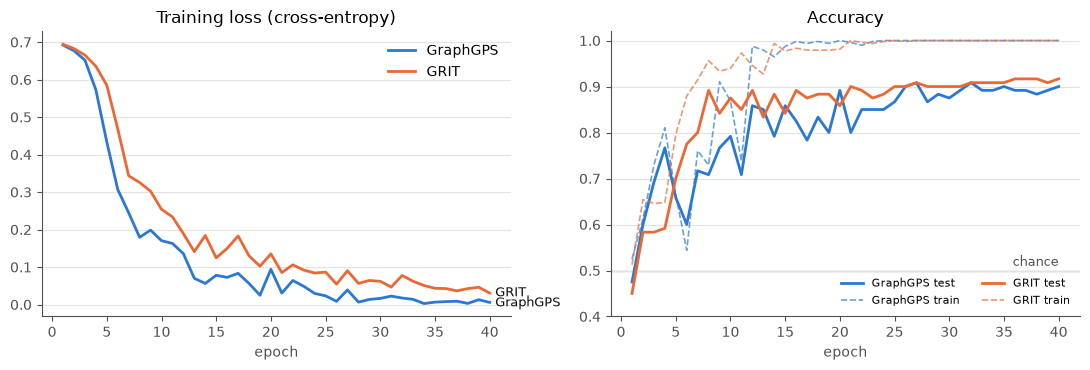

In [12]:
COLORS = {'GraphGPS': '#2a78d6', 'GRIT': '#eb6834'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 10})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, h in results.items():
    ep = np.arange(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['loss'], color=COLORS[name], lw=2, label=name)
    axes[1].plot(ep, h['test_acc'], color=COLORS[name], lw=2, label=f'{name} test')
    axes[1].plot(ep, h['train_acc'], color=COLORS[name], lw=1.2, ls='--', alpha=.7, label=f'{name} train')
    axes[0].annotate(name, (ep[-1], h['loss'][-1]), xytext=(4, 0), textcoords='offset points',
                     va='center', color='#0b0b0b', fontsize=9)
axes[1].axhline(0.5, color='#b5b4ad', lw=1, zorder=0); axes[1].text(40, 0.51, 'chance', ha='right', color='#52514e', fontsize=9)
axes[0].set(title='Training loss (cross-entropy)', xlabel='epoch')
axes[1].set(title='Accuracy', xlabel='epoch', ylim=(0.4, 1.02))
for ax in axes:
    ax.grid(axis='y', color='#e4e3dd', lw=.8); ax.set_axisbelow(True)
axes[0].legend(frameon=False); axes[1].legend(frameon=False, ncol=2, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

## 10. Inspecting attention

**GraphGPS.** When `log_attn_weights=True`, each `GPSLayer` stores `attn_weights` with shape `[num_graphs, heads, N_max, N_max]`. This is ordinary dense softmax attention over the padded node set.

**GRIT.** After a forward pass, `batch.attn` holds one score per *pair* in `batch.edge_index`, with shape `[P, heads, 1]`, from the **last** layer. Scattering it into an N×N matrix gives the same kind of picture.

The plots show one test graph: its adjacency, then the head-averaged last-layer attention of each model. Rows are the attending node (destination) and columns the attended node (source); each row sums to 1. If attention concentrates on real neighbours, the model has picked up the structure the task depends on.

avg share of attention on graph neighbours: GraphGPS=0.25  GRIT=0.36  (uniform baseline=0.25)


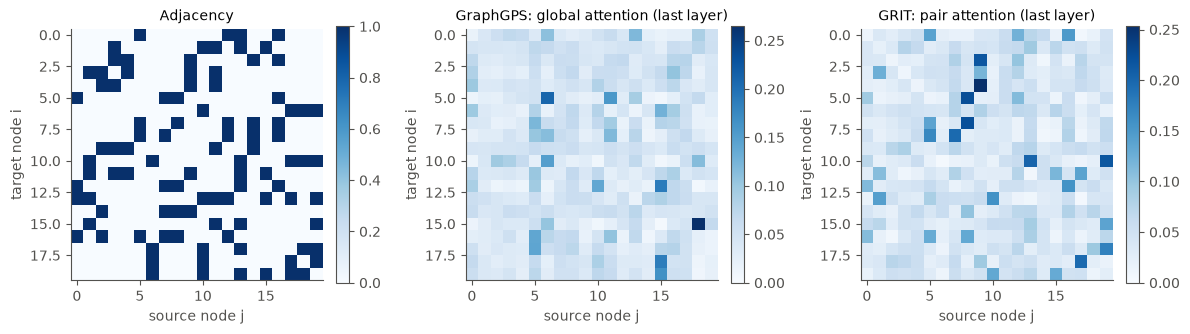

In [13]:
gps_model.eval(); grit_model.eval()
d = test_set[0]; n = d.num_nodes
with torch.no_grad():
    run(gps_model, [d])
    A_gps = gps_model.layers[-1].attn_weights[0].mean(0)[:n, :n]              # [n, n]
    _, _, b = run(grit_model, [d])
    att = b.attn.mean(1).squeeze(-1).cpu()                                     # [P]
    A_grit = torch.zeros(n, n); A_grit[b.edge_index[1].cpu(), b.edge_index[0].cpu()] = att
adj = to_dense_adj(d.edge_index, max_num_nodes=n)[0]

def neighbour_mass(A):   # share of each row's attention landing on real neighbours
    return (A * adj).sum(1).mean().item()

print(f'avg share of attention on graph neighbours: GraphGPS={neighbour_mass(A_gps):.2f}  '
      f'GRIT={neighbour_mass(A_grit):.2f}  (uniform baseline={adj.sum(1).mean().item()/n:.2f})')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, M, title in zip(axes, [adj, A_gps, A_grit],
                        ['Adjacency', 'GraphGPS: global attention (last layer)', 'GRIT: pair attention (last layer)']):
    im = ax.imshow(M, cmap='Blues', vmin=0)
    ax.set_title(title, fontsize=10); ax.set_xlabel('source node j'); ax.set_ylabel('target node i')
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

**Interpretation.** The two models split the work differently, and the neighbour-attention shares show it:

* **GraphGPS.** Global attention sits near the uniform baseline, because the local GatedGCN branch already handles neighbour-to-neighbour interactions. The Transformer branch only needs to spread global context, so its attention stays diffuse.
* **GRIT.** With no message-passing branch, attention *is* the only way to combine neighbours. It puts clearly more than the uniform share on real edges, having learned from the RRWP pair encoding which pairs are neighbours.

(The exact numbers depend on the seed and on which test graph is shown.)

## 11. Summary

| Check | GraphGPS | GRIT |
|---|---|---|
| Encodings consumed | `EigVals/EigVecs` (LapPE, EquivStableLapPE), `pestat_RWSE` | `rrwp`, `rrwp_index`, `rrwp_val`, `log_deg` |
| Configurations exercised | 16 (7 local MPNNs × PE variants, pure MPNN, pure Transformer, LayerNorm, node head) | 9 (full/sparse attention, no edge features, update_e, ReZero, LayerNorm, no deg-scaler, pooling, node head) |
| Output shapes / finite | ✔ | ✔ |
| Gradient flow | ✔ only the final layer's unused edge BatchNorm has no gradient | ✔ only the final layer's unused edge-output modules have no gradient |
| Permutation invariance | ✔ (with RWSE; LapPE is sign-ambiguous by nature) | ✔ |
| Learns the edge-dependent toy task (test acc, chance = 0.50) | ✔ ≈ 0.9 | ✔ ≈ 0.9 |

**Practical notes for using these on real EEG graphs:**

1. **Clone before every forward pass.** Both models write into `batch.x`, `batch.edge_attr` and (GRIT) `batch.edge_index`. The `DataLoader` builds fresh batches each epoch, so the usual loop is safe. Reusing one batch object is not.
2. **Precompute encodings in a transform.** `add_encodings` above can go in `Dataset.transform` / `pre_transform`. On larger graphs, sparse matrix powers are much cheaper than the dense ones used here.
3. **Watch GRIT's cost.** With `full_attn=True` it attends over $\sum_g N_g^2$ pairs per batch. For a 22–64-channel EEG montage that is cheap, but it grows quadratically.
4. **Always provide `log_deg` for GRIT.** Without it, the degree scaler receives the padded all-pairs degree, which is the same for every node (see the warning in §6).